# Data Analysis — Phishing URL Detection (Task 3)

Zhanna Azatkyzy, Dariyana Gabdylshukir

In this notebook we process the raw benchmark log `data/raw/test_run.jsonl`, calculate statistics and make the figures for the report.

Experiment: 4 models (Logistic Regression, Random Forest, SVM, XGBoost) × 2 feature sets (16 and 7 features) × 10 repeats. Dataset: 20 000 URLs, 16% phishing.

Steps:
1. Load data and remove warm-up
2. Statistics (median, p95, p99, 95% CI)
3. Figures

The functions used here are in `src/process_data.py` (data and statistics) and `src/visualize.py` (figures). The raw log was made by `src/run_experiment.py`.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import process_data as pr
import visualize as vis

np.random.seed(42)  # fixed seed for bootstrap
vis.setup_style()
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.4 | pandas 3.0.6


## 1. Data loading and warm-up filtering

Input: `data/raw/test_run.jsonl`, read by `load_raw()`.

The log has three types of records: `train` (training time), `quality` (confusion matrix on the test set) and `latency` (one inference request). For latency, the first 5 calls of every series are marked as `warmup`.

In [2]:
raw = pr.load_raw()
print("train records:", len(raw["train"]))
print("quality records:", len(raw["quality"]))
print("latency records:", len(raw["latency"]))
raw["latency"].head()

train records: 80
quality records: 80
latency records: 8000


,type,ts,model,feature_set,repeat,seed,batch_size,call,phase,latency_ms,status
0,latency,2026-11-03T20:28:52.195+00:00,logistic_regression,full,1,42,1,1,warmup,0.49174,ok
1,latency,2026-11-03T20:28:52.196+00:00,logistic_regression,full,1,42,1,2,warmup,0.28668,ok
2,latency,2026-11-03T20:28:52.197+00:00,logistic_regression,full,1,42,1,3,warmup,0.51319,ok
3,latency,2026-11-03T20:28:52.197+00:00,logistic_regression,full,1,42,1,4,warmup,0.63626,ok
4,latency,2026-11-03T20:28:52.198+00:00,logistic_regression,full,1,42,1,5,warmup,0.45530,ok


First calls are slower than the next ones (cold start), so we check this before removing them:

In [3]:
lat_raw = raw["latency"]
one = lat_raw[lat_raw["batch_size"] == 1]
one.groupby(["model", "phase"])["latency_ms"].median().unstack()

phase,eval,warmup
model,,
logistic_regression,0.314565,0.371130
random_forest,4.615810,4.727155
svm,0.502260,0.565070
xgboost,0.399825,0.446430


Warm-up calls have higher median latency for all models. If we keep them, p95 and p99 will be too high. So we remove them with `remove_warmup()`:

In [4]:
lat = pr.remove_warmup(raw["latency"])
print("before:", len(raw["latency"]), "after:", len(lat), "removed:", len(raw["latency"]) - len(lat))

before: 8000 after: 6400 removed: 1600


## 2. Statistics

### 2.1 Quality metrics

For each of 10 repeats we calculate precision, recall, F1 and accuracy from the confusion matrix (`add_metrics()`).

In [5]:
q = pr.add_metrics(raw["quality"])
q[["model", "feature_set", "repeat", "precision", "recall", "f1", "accuracy"]].head(8)

,model,feature_set,repeat,precision,recall,f1,accuracy
0,logistic_regression,full,1,0.849765,0.186791,0.306261,0.863333
1,random_forest,full,1,0.734353,0.544892,0.625592,0.894667
2,svm,full,1,0.901460,0.254902,0.397426,0.875167
3,xgboost,full,1,0.786885,0.495356,0.607980,0.896833
4,logistic_regression,selected,1,0.955224,0.132095,0.232094,0.858833
5,random_forest,selected,1,0.616379,0.295150,0.399163,0.856500
6,svm,selected,1,0.894444,0.166151,0.280244,0.862167
7,xgboost,selected,1,0.765244,0.259030,0.387047,0.867500


F1 for each model: mean ± SD and 95% bootstrap confidence interval of the mean (`bootstrap_ci()`, 10 000 resamples, seed 42).

In [6]:
rows = []
for (model, fs), g in q.groupby(["model", "feature_set"]):
    lo, hi = pr.bootstrap_ci(g["f1"])
    rows.append([model, fs, g["f1"].mean(), g["f1"].std(), lo, hi, g["accuracy"].mean()])
f1_table = pd.DataFrame(rows, columns=["model", "features", "f1_mean", "f1_sd",
                                        "ci_low", "ci_high", "accuracy"])
f1_table.round(3)

,model,features,f1_mean,f1_sd,ci_low,ci_high,accuracy
0,logistic_regression,full,0.314,0.015,0.305,0.323,0.864
1,logistic_regression,selected,0.226,0.018,0.215,0.236,0.857
2,random_forest,full,0.639,0.011,0.632,0.645,0.898
3,random_forest,selected,0.400,0.020,0.389,0.412,0.855
4,svm,full,0.403,0.020,0.391,0.414,0.876
5,svm,selected,0.287,0.017,0.277,0.297,0.863
6,xgboost,full,0.626,0.016,0.616,0.635,0.903
7,xgboost,selected,0.385,0.014,0.377,0.393,0.868


Accuracy is 0.85–0.90 for all models, but a model that always says "benign" already gets 0.84 (because 84% of URLs are benign). That is why we use F1 for the phishing class as the main metric.

### 2.2 Latency

Median, p25, p75, p95, p99 and 95% CI of the median for every model and load (`latency_table()`). This table is used for Figure 1.

In [7]:
lat_tab = pr.latency_table(lat)
lat_tab.round(3)

,model,feature_set,batch_size,n,median,p25,p75,p95,p99,ci_low,ci_high
0,logistic_regression,full,1,200,0.331,0.278,0.404,0.583,0.690,0.312,0.345
1,logistic_regression,full,10,200,0.375,0.324,0.501,0.735,2.725,0.361,0.395
2,logistic_regression,full,100,200,0.780,0.703,0.867,1.014,1.304,0.767,0.799
3,logistic_regression,full,1000,200,4.456,4.115,4.701,6.994,7.569,4.422,4.523
4,logistic_regression,selected,1,200,0.308,0.266,0.364,0.458,0.630,0.295,0.316
5,logistic_regression,selected,10,200,0.355,0.317,0.401,0.503,0.716,0.341,0.363
6,logistic_regression,selected,100,200,0.754,0.698,0.806,0.897,1.110,0.742,0.764
7,logistic_regression,selected,1000,200,4.409,4.277,4.553,5.215,5.776,4.388,4.438
8,random_forest,full,1,200,4.660,4.185,5.134,5.985,6.454,4.545,4.789
9,random_forest,full,10,200,5.218,4.499,5.704,6.372,7.438,4.968,5.392


### 2.3 Guardrails

- error rate = 0
- recall ≥ 0.80
- p99 latency for 1 URL ≤ 100 ms

Calculated by `check_guardrails()`.

In [8]:
guard = pr.check_guardrails(q, raw["latency"], lat)
guard.round(3)

,model,feature_set,error_rate,recall,p99_ms,recall_ok,latency_ok,errors_ok
0,logistic_regression,full,0.0,0.192,0.690,False,True,True
1,logistic_regression,selected,0.0,0.129,0.630,False,True,True
2,random_forest,full,0.0,0.557,6.454,False,True,True
3,random_forest,selected,0.0,0.300,8.381,False,True,True
4,svm,full,0.0,0.260,0.949,False,True,True
5,svm,selected,0.0,0.171,0.758,False,True,True
6,xgboost,full,0.0,0.504,0.739,False,True,True
7,xgboost,selected,0.0,0.256,0.933,False,True,True


### 2.4 Summary table

This table is saved to `data/processed/metrics_summary.csv` and used in README.

In [9]:
summary = pr.make_summary(q, lat_tab, guard)
summary.to_csv("../data/processed/metrics_summary.csv", index=False, float_format="%.4f")
lat_tab.to_csv("../data/processed/latency_summary.csv", index=False, float_format="%.4f")

from IPython.display import Markdown
Markdown(pr.results_table(summary))

| Model | Features | Role | F1 (Mean ± SD) | F1 95% CI | Recall (Mean ± SD) | Latency 1 URL, ms (Median, p25–p75) | p99, ms |
|---|---|---|---|---|---|---|---|
| Logistic Regression | full | **Baseline** | 0.314 ± 0.015 | [0.305, 0.323] | 0.192 ± 0.012 | 0.33 (0.28–0.40) | 0.69 |
| Random Forest | full | Proposed | 0.639 ± 0.011 | [0.632, 0.645] | 0.557 ± 0.010 | 4.66 (4.19–5.13) | 6.45 |
| SVM | full | Proposed | 0.403 ± 0.020 | [0.391, 0.414] | 0.260 ± 0.016 | 0.55 (0.49–0.59) | 0.95 |
| XGBoost | full | Proposed | 0.626 ± 0.016 | [0.616, 0.635] | 0.504 ± 0.019 | 0.40 (0.34–0.47) | 0.74 |
| Logistic Regression | selected | Proposed | 0.226 ± 0.018 | [0.215, 0.236] | 0.129 ± 0.012 | 0.31 (0.27–0.36) | 0.63 |
| Random Forest | selected | Proposed | 0.400 ± 0.020 | [0.389, 0.412] | 0.300 ± 0.019 | 4.49 (3.91–5.10) | 8.38 |
| SVM | selected | Proposed | 0.287 ± 0.017 | [0.277, 0.297] | 0.171 ± 0.012 | 0.47 (0.41–0.51) | 0.76 |
| XGBoost | selected | Proposed | 0.385 ± 0.014 | [0.377, 0.393] | 0.256 ± 0.012 | 0.40 (0.35–0.44) | 0.93 |

## 3. Figures

Figures are made by `src/visualize.py` and saved to `reports/figures/` as PDF and PNG (300 dpi) with `save()`.

**Figure 1.** Latency vs load. Log scale on both axes because values go from 0.3 ms to 150 ms. Error bars show 95% CI of the median, the band shows p25–p75.

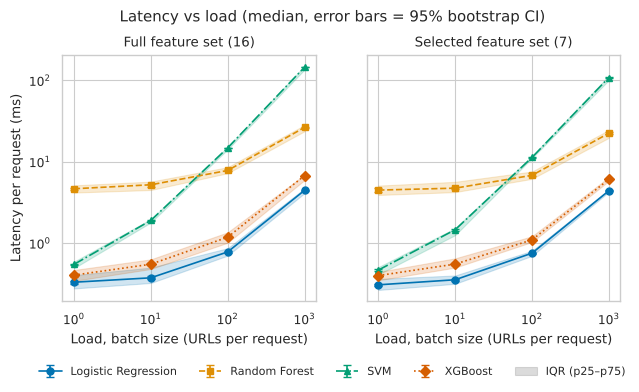

In [10]:
fig = vis.plot_latency_vs_load(lat_tab)
vis.save(fig, "fig1_latency_vs_load")
plt.show()

**Figure 2.** (a) F1 over 10 repeats, (b) latency for one URL. Black diamonds show the mean / median with 95% CI.

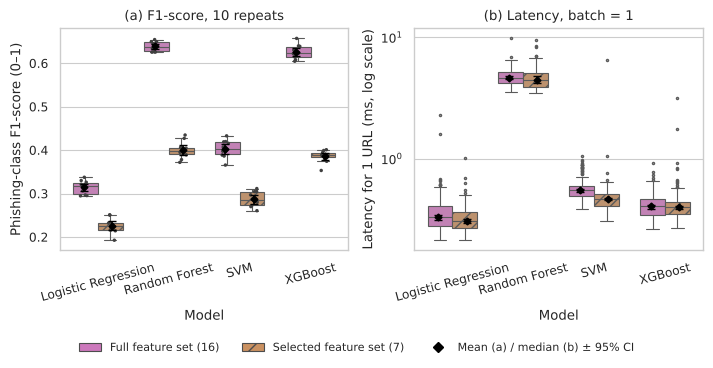

In [11]:
fig = vis.plot_boxplots(q, lat)
vis.save(fig, "fig2_distribution_boxplot")
plt.show()

## 4. Conclusions

- **RQ1.** Random Forest (F1 = 0.64) and XGBoost (F1 = 0.63) are about 2 times better than the baseline Logistic Regression (F1 = 0.31). Confidence intervals do not overlap, so the difference is real.
- **RQ2a.** With 7 features F1 goes down for all models (for example Random Forest 0.64 → 0.40). The full feature set is better.
- **RQ2b.** Latency almost does not change with 7 features (differences are less than 0.2 ms), because most of the time is spent on feature extraction, not on the model.
- **RQ3.** Logistic Regression and XGBoost are the fastest (~0.3–0.4 ms per URL), Random Forest is slower (~4.7 ms). SVM becomes very slow with large batches. XGBoost gives the best balance between quality and speed.
- **Guardrails.** All models have 0 errors and p99 latency below 10 ms. But no model reaches recall 0.80 (best is Random Forest with 0.56). So simple lexical features are not enough, and in future work we can try class weights, another threshold or more features.